# Multi-modal: tiles with expression

A batch can hold every element of a cell at once: its expression from the `table`, a tile of each image and a tile of each labels element, all aligned along axis 0.
This guide streams the `he_image` (H&E) image together with the expression of real Xenium slides and trains a small model that **predicts a cell's gene expression from its image**.

It reads the same collection as {doc}`scrnaseq` (table only) and {doc}`images` (pixels only); only the loader changes.
If you are new to `spatialbatch`, skim the {doc}`quickstart` first.

## Configure zarrs

In [1]:
import os
import warnings
from pathlib import Path

import zarr

zarr.config.set({"codec_pipeline.path": "zarrs.ZarrsCodecPipeline"})
for msg in (
    "Consolidated metadata is currently not part in the Zarr format 3 specification.*",
    "The index of the dataframe is not monotonic increasing.*",
):
    warnings.filterwarnings("ignore", message=msg)

## Get the data

In [2]:
# Xenium stores read with `spatialdata-io`; point SPATIALBATCH_DATA at the folder that holds them.
DATA = Path(os.environ.get("SPATIALBATCH_DATA", "sddb-downloads"))
STORES = [DATA / "6T1aLES2sndpL1bQ0001.zarr", DATA / "ftcwfWqbDwNk5EMp0001.zarr"]
# The collection shared by the scrnaseq, images and multimodal tutorials.
COLLECTION = Path(os.environ.get("SPATIALBATCH_COLLECTION", "sddb_collection.zarr"))

## Write the collection (once)

This tutorial, {doc}`scrnaseq`, {doc}`images` and {doc}`multimodal` share **one** collection holding the table, the `morphology_focus` (DAPI) and `he_image` (H&E) images and the `cell_labels` and `nucleus_labels` masks of every slide; each only changes how the {class}`~spatialbatch.Loader` is built.
It is written by whichever tutorial runs first and reused by the others.

`load_table` plays the role of annbatch's `load_adata`: it chooses what of the table is written.
Here we keep the raw counts in `X`, three `obs` columns and the cell coordinates, and drop the duplicate `csc_counts` layer.
It must keep the rows: they are tied to the tiles.

In [3]:
import anndata as ad

from spatialbatch import SpatialDatasetCollection


def _load_table(table: ad.AnnData) -> ad.AnnData:
    return ad.AnnData(
        X=table.X.astype("float32"),  # raw counts, one dtype across slides
        obs=table.obs[["cell_id", "cell_area", "total_counts"]],
        var=table.var,
        obsm={"spatial": table.obsm["spatial"]},
    )


if not COLLECTION.exists():
    SpatialDatasetCollection(zarr.open_group(COLLECTION, mode="w")).add_sdatas(
        STORES,
        region="cell_circles",
        images=["morphology_focus", "he_image"],
        labels=["cell_labels", "nucleus_labels"],
        load_table=_load_table,
    )
collection = SpatialDatasetCollection(zarr.open_group(COLLECTION, mode="r"))
for dataset in collection:
    meta = dataset.attrs["spatialbatch"]
    print(
        f"{dataset.name}: {dataset['obsm']['spatial'].shape[0]:,} cells | tiles {meta['tile_hw']} | "
        f"images {meta['images']} | labels {meta['labels']}"
    )

/Users/rushin.gindra/Documents/Research/SpatialProjects/spatialdatabase/spatialbatch/.claude/worktrees/add-tutorials/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/dataset_0: 348,141 cells | tiles [1024, 1024] | images ['morphology_focus', 'he_image'] | labels ['cell_labels', 'nucleus_labels']
/dataset_1: 247,876 cells | tiles [1024, 1024] | images ['morphology_focus', 'he_image'] | labels ['cell_labels', 'nucleus_labels']


## Stream tiles and expression together

With `table=True` (the default) and `images=[...]`, every batch has `X`, `obs`, `coords` and the image tiles of the same cells, in the same order.

In [4]:
import torch

from spatialbatch import Loader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

loader = Loader(
    images=["he_image"], return_annotations=["cell_id", "total_counts"], batch_size=32, shuffle=True, to="torch"
).use_collection(collection)
batch = next(iter(loader))
for key in ("X", "obs", "coords"):
    print(f"{key:7} {tuple(batch[key].shape)}")
print(f"images  {tuple(batch['images']['he_image'].shape)}")
genes = batch["var"].index

X       (32, 479)
obs     (32, 2)
coords  (32, 2)
images  (32, 3, 1024, 1024)


One row of the batch: the cell's tile, and its most expressed genes.

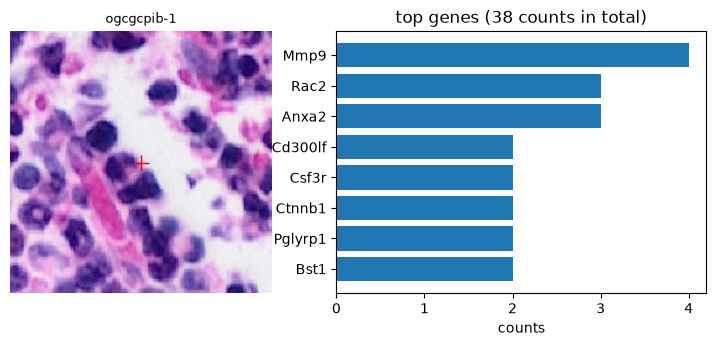

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision.transforms import v2


def as_rgb(tile: torch.Tensor) -> torch.Tensor:
    """A (3, H, W) H&E tile as an (H, W, 3) uint8 image, the layout imshow expects."""
    return tile.permute(1, 2, 0).clamp(0, 255).to(torch.uint8).cpu()


row = 0
tile = v2.CenterCrop(224)(batch["images"]["he_image"])[row]
counts = batch["X"][row].to_dense().numpy()
top = np.argsort(counts)[::-1][:8]

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(9, 3.4), width_ratios=[1, 1.4])
c = tile.shape[-1] // 2  # the center pixel of the crop
ax_img.imshow(as_rgb(tile))
ax_img.plot(c, c, "r+", markersize=12)  # the center of the crop: the cell this row belongs to
ax_img.set_title(batch["obs"]["cell_id"].iloc[row], fontsize=9)
ax_img.axis("off")
ax_bar.barh(genes[top][::-1], counts[top][::-1])
ax_bar.set(xlabel="counts", title=f"top genes ({int(batch['obs']['total_counts'].iloc[row])} counts in total)");

## One transform for every element

The transform prepares the whole batch for the model, on the device:

- **image**: center crop the 3-channel H&E tile to 224 pixels, random flips per cell, log and standardize;
- **expression**: densify, normalize each cell to 10,000 counts and `log1p`: the regression target.

In [6]:
CROP = 224


def make_transform(crop: int = 224):
    center = v2.CenterCrop(crop)

    def transform(batch):
        tiles = center(batch["images"]["he_image"]).to(device).float()
        flip = torch.rand(tiles.shape[0], device=device) < 0.5
        tiles = torch.where(flip[:, None, None, None], tiles.flip(-1), tiles)
        tiles = torch.log1p(tiles)
        tiles = (tiles - tiles.mean(dim=(-2, -1), keepdim=True)) / tiles.std(dim=(-2, -1), keepdim=True).clamp(min=1e-3)

        x = batch["X"].to(device).to_dense()
        x = torch.log1p(x / x.sum(dim=1, keepdim=True).clamp(min=1) * 1e4)
        return {"image": tiles, "expression": x, "obs": batch["obs"]}

    return transform


train_loader = Loader(
    images=["he_image"],
    return_annotations=["cell_id"],
    batch_size=64,
    chunk_size=16,
    preload_nchunks=16,
    shuffle=True,
    to="torch",
    transform=make_transform(CROP),
).use_collection(collection)
batch = next(iter(train_loader))
print({k: tuple(v.shape) for k, v in batch.items() if k != "obs"})

{'image': (64, 3, 224, 224), 'expression': (64, 479)}


## Train a model on the batches

A small CNN encodes the 224-pixel tile, and a linear head predicts the 479 normalized gene expression values.
It only shows how batches feed a model: train longer, and on a GPU, for a useful one.

In [7]:
from torch import nn

n_genes = batch["expression"].shape[1]
model = nn.Sequential(
    nn.Conv2d(3, 16, 5, stride=2, padding=2),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(64, n_genes),
).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

losses = []
for step, batch in enumerate(train_loader):
    loss = nn.functional.mse_loss(model(batch["image"]), batch["expression"])
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if step % 25 == 0:
        print(f"step {step:3d}  loss {loss.item():.3f}")
    if step == 150:
        break

step   0  loss 1.995


step  25  loss 1.499


step  50  loss 1.377


step  75  loss 1.391


step 100  loss 1.497


step 125  loss 1.486


step 150  loss 1.383


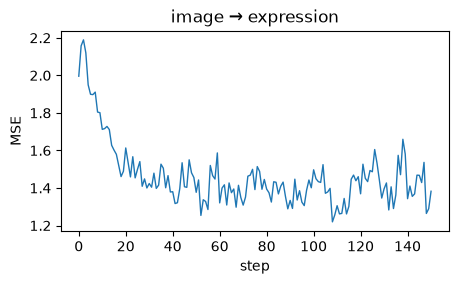

In [8]:
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(losses, lw=1)
ax.set(xlabel="step", ylabel="MSE", title="image → expression");

## Next steps

- Add `labels=["cell_labels"]` to the loader for the segmentation mask, augmented together with the image as in {doc}`images`.
- `coords` gives each cell's position, for models of spatial neighborhoods.
- Coming from `spatialstream`'s `XeniumDataset`? `spatialbatch.utils.to_spatialstream_batch` reshapes a batch to what it yields.